In [13]:
import sys, subprocess
try:
    import umap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "umap-learn"])
    import umap

import json, random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, silhouette_samples

from utils import load, center_normalize, label_colors, COLOR_I, COLOR_T, COLOR_HIGHLIGHT

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

I_raw, T_raw, Y = load()
Xs = {"I": center_normalize(I_raw), "T": center_normalize(T_raw)}
COLORS = label_colors(Y)
LABELS = np.unique(Y)
MODCOL = {"I": COLOR_I, "T": COLOR_T}
res_dir = Path("../results"); res_dir.mkdir(exist_ok=True)
fig_dir = Path("../figures"); fig_dir.mkdir(exist_ok=True)
RC = {"font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7,
      "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6}
point_colors = np.array([COLORS[int(y)] for y in Y], dtype=object)

def scatter_labels(ax, xy, s=3, annotate=False, fontsize=6):
    """Scatter coloured by label; label 34 drawn first (underneath) in grey."""
    order = np.argsort(Y != 34, kind="stable")  # 34 first
    ax.scatter(xy[order, 0], xy[order, 1], s=s, c=list(point_colors[order]), linewidths=0)
    if annotate:
        for l in LABELS:
            m = np.median(xy[Y == l], axis=0)
            ax.text(m[0], m[1], str(l), fontsize=fontsize, ha="center", va="center",
                    fontweight="bold", color="black",
                    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.6))
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal", adjustable="datalim")

## 1. PCA

### 1a. Explained variance

In [2]:
pcas, cum = {}, {}
summary = {"pca": {}}
for name, X in Xs.items():
    p = PCA(random_state=SEED).fit(X)
    pcas[name] = p
    cum[name] = np.cumsum(p.explained_variance_ratio_)
    ncomp = [int(np.searchsorted(cum[name], t) + 1) for t in (0.5, 0.9, 0.95)]
    ev = p.explained_variance_ratio_
    print(f"{name}: PC1={ev[0]:.3f} PC2={ev[1]:.3f}  components for 50/90/95% = {ncomp}")
    summary["pca"][name] = {"pc1": round(float(ev[0]), 4), "pc2": round(float(ev[1]), 4),
                            "n_components_50_90_95": ncomp}

I: PC1=0.109 PC2=0.078  components for 50/90/95% = [10, 92, 160]
T: PC1=0.151 PC2=0.089  components for 50/90/95% = [10, 103, 176]


### 1b. Cumulative explained variance

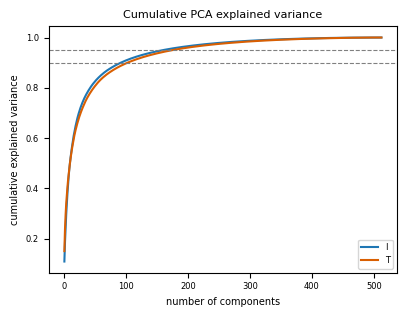

In [3]:
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(4.5, 3.2))
    for name in Xs:
        ax.plot(np.arange(1, len(cum[name]) + 1), cum[name], color=MODCOL[name], label=name)
    for h in (0.9, 0.95):
        ax.axhline(h, color="gray", ls="--", lw=0.8)
    ax.set_xlabel("number of components"); ax.set_ylabel("cumulative explained variance")
    ax.set_title("Cumulative PCA explained variance"); ax.legend()
    plt.show()

### 1c. PC1 vs PC2

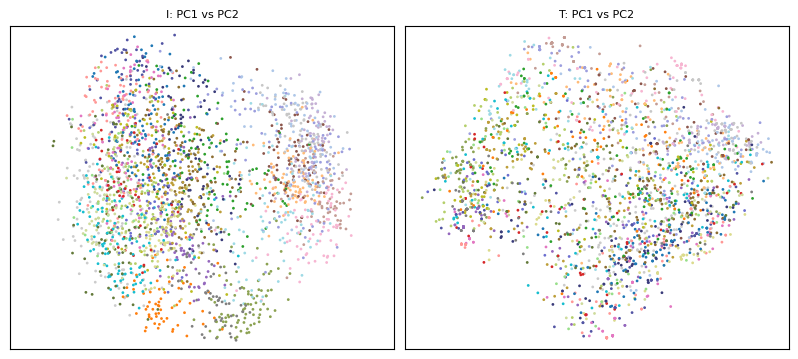

In [4]:
with plt.rc_context(RC):
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
    for ax, name in zip(axes, Xs):
        Z = pcas[name].transform(Xs[name])[:, :2]
        scatter_labels(ax, Z, s=4)
        ax.set_title(f"{name}: PC1 vs PC2")
    plt.tight_layout(); plt.show()

## 2. Non-linear 2D maps

### 2a. UMAP (with 2c: class labels at 2D medians)

/Users/gayathriharshila/Desktop/jepa-task/.venv/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/gayathriharshila/Desktop/jepa-task/.venv/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/gayathriharshila/Desktop/jepa-task/.venv/lib/python3.10/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


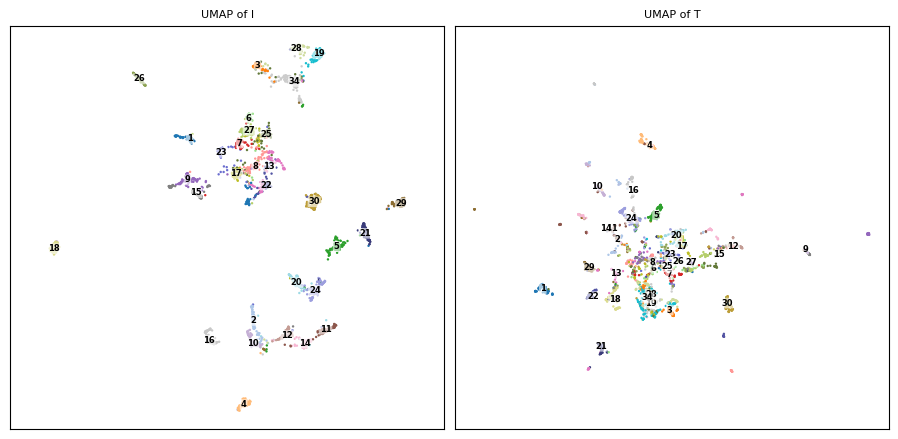

In [5]:
emb_umap = {}
for name, X in Xs.items():
    emb_umap[name] = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine",
                               random_state=SEED).fit_transform(X)
    np.save(res_dir / f"umap_{name}.npy", emb_umap[name])

with plt.rc_context(RC):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
    for ax, name in zip(axes, Xs):
        scatter_labels(ax, emb_umap[name], s=3, annotate=True)
        ax.set_title(f"UMAP of {name}")
    plt.tight_layout(); plt.show()

### 2b. t-SNE

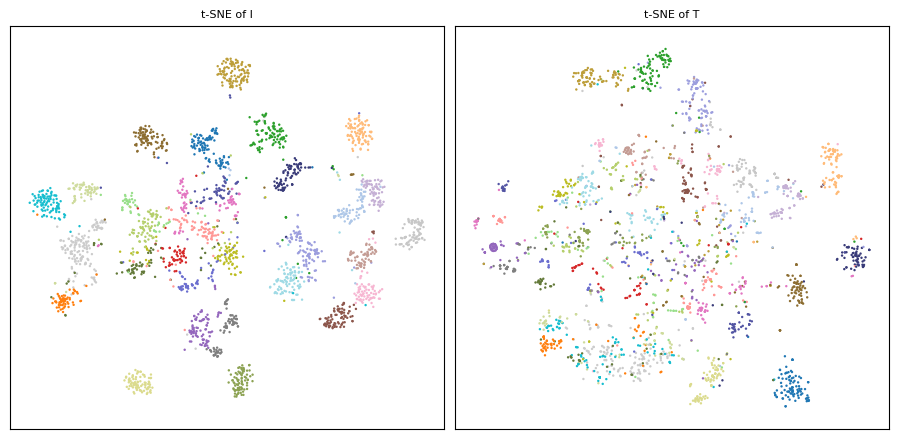

In [6]:
emb_tsne = {}
for name, X in Xs.items():
    emb_tsne[name] = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca",
                          random_state=SEED).fit_transform(X)
    np.save(res_dir / f"tsne_{name}.npy", emb_tsne[name])

with plt.rc_context(RC):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
    for ax, name in zip(axes, Xs):
        scatter_labels(ax, emb_tsne[name], s=3)
        ax.set_title(f"t-SNE of {name}")
    plt.tight_layout(); plt.show()

### 3a. Silhouette (cosine, labels = Y)

In [7]:
sil = {n: float(silhouette_score(X, Y, metric="cosine")) for n, X in Xs.items()}
print({n: round(v, 3) for n, v in sil.items()})
summary["silhouette"] = {n: round(v, 4) for n, v in sil.items()}

{'I': 0.193, 'T': 0.112}


### 3b. Per-class silhouette

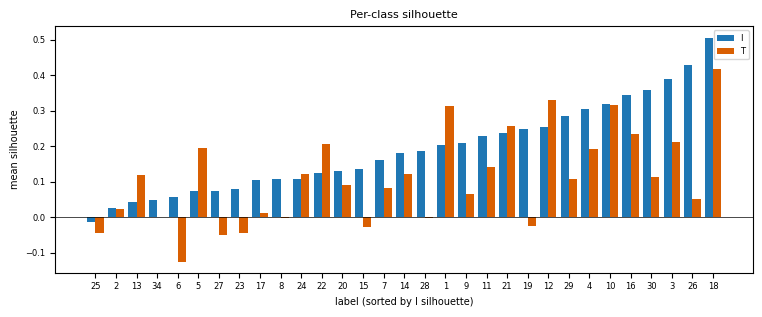

I: 5 worst classes [(25, -0.013), (2, 0.025), (13, 0.042), (34, 0.048), (6, 0.056)]; label 34 silhouette 0.048, rank 4 of 31 (1 = worst)
T: 5 worst classes [(6, -0.125), (27, -0.05), (25, -0.046), (23, -0.045), (15, -0.027)]; label 34 silhouette 0.001, rank 9 of 31 (1 = worst)


In [8]:
per_class = {}
for n, X in Xs.items():
    s = silhouette_samples(X, Y, metric="cosine")
    per_class[n] = {int(l): float(s[Y == l].mean()) for l in LABELS}

order = sorted(LABELS, key=lambda l: per_class["I"][int(l)])
x = np.arange(len(order)); w = 0.4
with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.bar(x - w/2, [per_class["I"][int(l)] for l in order], w, color=COLOR_I, label="I")
    ax.bar(x + w/2, [per_class["T"][int(l)] for l in order], w, color=COLOR_T, label="T")
    ax.set_xticks(x); ax.set_xticklabels(order); ax.axhline(0, color="k", lw=0.5)
    ax.set_xlabel("label (sorted by I silhouette)"); ax.set_ylabel("mean silhouette")
    ax.set_title("Per-class silhouette"); ax.legend()
    plt.show()

worst, rank34_sil = {}, {}
for n in Xs:
    asc = sorted(per_class[n], key=per_class[n].get)
    worst[n] = asc[:5]
    rank34_sil[n] = asc.index(34) + 1   # 1 = worst
    print(f"{n}: 5 worst classes {[(l, round(per_class[n][l], 3)) for l in asc[:5]]}; "
          f"label 34 silhouette {per_class[n][34]:.3f}, rank {rank34_sil[n]} of {len(asc)} (1 = worst)")

### 3c. Compactness (label 34 check)

In [9]:
compact = {}
for n, X in Xs.items():
    compact[n] = {}
    for l in LABELS:
        Xc = X[Y == l]
        c = Xc.mean(0); c /= np.linalg.norm(c)
        compact[n][int(l)] = float((Xc @ c).mean())
    asc = sorted(compact[n], key=compact[n].get)
    print(f"{n}: compactness per class (mean cos to class centroid)")
    print("  " + ", ".join(f"{l}:{compact[n][l]:.3f}" for l in sorted(compact[n])))
    print(f"  least compact: {asc[0]}; label 34 rank {asc.index(34)+1} of {len(asc)} (1 = least compact); "
          f"34 is least compact: {asc[0] == 34}")
rank34_comp = {n: sorted(compact[n], key=compact[n].get).index(34) + 1 for n in Xs}

I: compactness per class (mean cos to class centroid)
  1:0.635, 2:0.649, 3:0.761, 4:0.750, 5:0.567, 6:0.602, 7:0.626, 8:0.605, 9:0.674, 10:0.775, 11:0.697, 12:0.751, 13:0.564, 14:0.715, 15:0.674, 16:0.766, 17:0.576, 18:0.771, 19:0.738, 20:0.618, 21:0.638, 22:0.628, 23:0.582, 24:0.631, 25:0.534, 26:0.782, 27:0.571, 28:0.718, 29:0.669, 30:0.703, 34:0.602
  least compact: 25; label 34 rank 8 of 31 (1 = least compact); 34 is least compact: False
T: compactness per class (mean cos to class centroid)
  1:0.687, 2:0.570, 3:0.626, 4:0.626, 5:0.631, 6:0.402, 7:0.554, 8:0.539, 9:0.650, 10:0.710, 11:0.596, 12:0.713, 13:0.609, 14:0.621, 15:0.607, 16:0.683, 17:0.538, 18:0.739, 19:0.477, 20:0.569, 21:0.648, 22:0.625, 23:0.453, 24:0.593, 25:0.474, 26:0.520, 27:0.472, 28:0.489, 29:0.523, 30:0.559, 34:0.435
  least compact: 6; label 34 rank 2 of 31 (1 = least compact); 34 is least compact: False


### 3d. Shared-target check

largest shared-T group: 30 rows, labels [9]


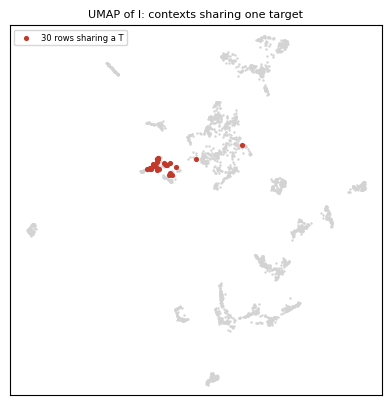

mean pairwise cosine, shared-target group: 0.433
mean pairwise cosine, random label-9 rows (mean of 200 draws): 0.449 (std 0.027)


In [10]:
_, inv, cnt = np.unique(T_raw, axis=0, return_inverse=True, return_counts=True)
inv = inv.ravel()
g = int(np.argmax(cnt))
idx = np.flatnonzero(inv == g)
print(f"largest shared-T group: {len(idx)} rows, labels {np.unique(Y[idx])}")
lab_g = int(Y[idx][0])

with plt.rc_context(RC):
    fig, ax = plt.subplots(figsize=(4.8, 4.8))
    U = emb_umap["I"]
    ax.scatter(U[:, 0], U[:, 1], s=3, c="lightgrey", linewidths=0)
    ax.scatter(U[idx, 0], U[idx, 1], s=14, c="#c0392b", linewidths=0, label=f"{len(idx)} rows sharing a T")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal", adjustable="datalim")
    ax.set_title("UMAP of I: contexts sharing one target"); ax.legend()
    plt.show()

def mean_pairwise(X):
    S = X @ X.T
    return float(S[np.triu_indices(len(X), k=1)].mean())

XI = Xs["I"]
group_sim = mean_pairwise(XI[idx])
rng = np.random.default_rng(SEED)
pool = np.flatnonzero(Y == lab_g)
rand_sims = [mean_pairwise(XI[rng.choice(pool, len(idx), replace=False)]) for _ in range(200)]
rand_sim = float(np.mean(rand_sims))
print(f"mean pairwise cosine, shared-target group: {group_sim:.3f}")
print(f"mean pairwise cosine, random label-{lab_g} rows (mean of 200 draws): {rand_sim:.3f} "
      f"(std {np.std(rand_sims):.3f})")

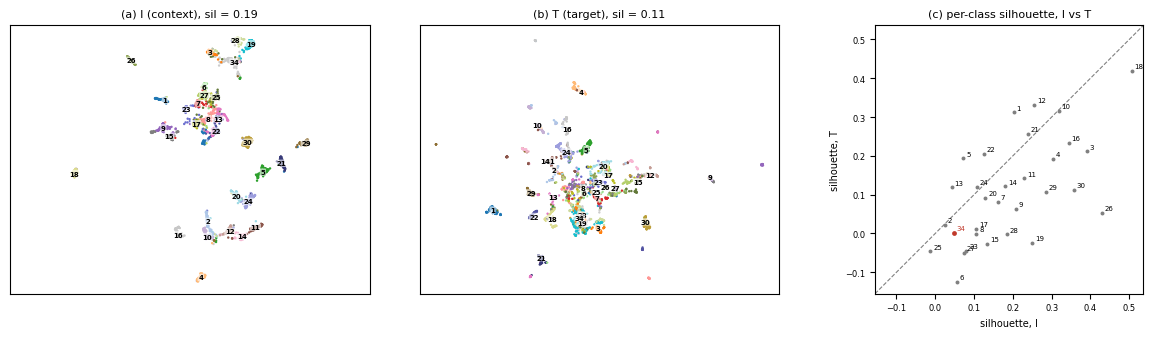

In [11]:
with plt.rc_context(RC):
    fig, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=(12, 3.4))
    scatter_labels(ax_a, emb_umap["I"], s=3, annotate=True, fontsize=5)
    ax_a.set_title(f"(a) I (context), sil = {sil['I']:.2f}")
    scatter_labels(ax_b, emb_umap["T"], s=3, annotate=True, fontsize=5)
    ax_b.set_title(f"(b) T (target), sil = {sil['T']:.2f}")
    xs = np.array([per_class["I"][int(l)] for l in LABELS])
    ys = np.array([per_class["T"][int(l)] for l in LABELS])
    lo = min(xs.min(), ys.min()) - 0.03
    hi = max(xs.max(), ys.max()) + 0.03
    ax_c.plot([lo, hi], [lo, hi], color="gray", ls="--", lw=0.8)
    is34 = LABELS == 34
    ax_c.scatter(xs[~is34], ys[~is34], s=8, color="gray", linewidths=0)
    ax_c.scatter(xs[is34], ys[is34], s=12, color=COLOR_HIGHLIGHT, linewidths=0)
    for l, x_, y_ in zip(LABELS, xs, ys):
        ax_c.annotate(str(l), (x_, y_), fontsize=5, xytext=(2, 2), textcoords="offset points",
                      color=COLOR_HIGHLIGHT if l == 34 else "black")
    ax_c.set_xlim(lo, hi); ax_c.set_ylim(lo, hi); ax_c.set_aspect("equal")
    ax_c.set_xlabel("silhouette, I"); ax_c.set_ylabel("silhouette, T")
    ax_c.set_title("(c) per-class silhouette, I vs T")
    plt.tight_layout()
    fig.savefig(fig_dir / "fig2_structure.pdf", bbox_inches="tight")
    fig.savefig(fig_dir / "fig2_structure.png", dpi=200, bbox_inches="tight")
    plt.show()

In [12]:
summary["per_class_worst5"] = {n: [int(l) for l in worst[n]] for n in Xs}
summary["label34_rank_by_silhouette_1_is_worst"] = {n: int(rank34_sil[n]) for n in Xs}
summary["label34_rank_by_compactness_1_is_least_compact"] = {n: int(rank34_comp[n]) for n in Xs}
summary["shared_target_check"] = {
    "group_size": int(len(idx)), "group_label": lab_g,
    "mean_pairwise_cos_I_shared_target_group": round(group_sim, 4),
    "mean_pairwise_cos_I_random_same_class": round(rand_sim, 4),
}
print(json.dumps(summary, indent=2))
with open(res_dir / "step2_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

{
  "pca": {
    "I": {
      "pc1": 0.1095,
      "pc2": 0.0775,
      "n_components_50_90_95": [
        10,
        92,
        160
      ]
    },
    "T": {
      "pc1": 0.1509,
      "pc2": 0.0885,
      "n_components_50_90_95": [
        10,
        103,
        176
      ]
    }
  },
  "silhouette": {
    "I": 0.1926,
    "T": 0.1119
  },
  "per_class_worst5": {
    "I": [
      25,
      2,
      13,
      34,
      6
    ],
    "T": [
      6,
      27,
      25,
      23,
      15
    ]
  },
  "label34_rank_by_silhouette_1_is_worst": {
    "I": 4,
    "T": 9
  },
  "label34_rank_by_compactness_1_is_least_compact": {
    "I": 8,
    "T": 2
  },
  "shared_target_check": {
    "group_size": 30,
    "group_label": 9,
    "mean_pairwise_cos_I_shared_target_group": 0.4327,
    "mean_pairwise_cos_I_random_same_class": 0.4493
  }
}
